In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Data Exploration

In [ ]:
fraud_data = pd.read_csv("https://raw.githubusercontent.com/dphi-official/Imbalanced_classes/master/fraud_data.csv")
fraud_data.head()

,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
0,2994681,0,242834,25.000,H,9803,583.0,150.0,visa,226.0,...,firefox 56.0,24.0,1920x1080,match_status:2,T,F,T,T,desktop,rv:56.0
1,3557242,0,15123000,117.000,W,7919,194.0,150.0,mastercard,166.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3327470,0,8378575,73.773,C,12778,500.0,185.0,mastercard,224.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3118781,0,2607840,400.000,R,12316,548.0,150.0,visa,195.0,...,mobile safari generic,32.0,1136x640,match_status:2,T,F,T,F,mobile,iOS Device
4,3459772,0,12226544,31.950,W,9002,453.0,150.0,visa,226.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
fraud_data.shape

(59054, 434)

There are 59054 observations and 434 features

In [ ]:
fraud_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 59054 entries, 0 to 59053
Columns: 434 entries, TransactionID to DeviceInfo
dtypes: float64(385), int64(18), object(31)
memory usage: 195.5+ MB


In [ ]:
fraud_data.describe()

,TransactionID,isFraud,TransactionDT,TransactionAmt,card1,card2,card3,card5,addr1,addr2,...,id_17,id_18,id_19,id_20,id_21,id_22,id_24,id_25,id_26,id_32
count,5.905400e+04,59054.000000,5.905400e+04,59054.000000,59054.000000,58139.000000,58896.000000,58610.000000,52326.000000,52326.000000,...,14061.00000,4511.000000,14059.000000,14054.000000,525.000000,525.000000,487.000000,524.000000,525.000000,7715.000000
mean,3.282166e+06,0.033952,7.368220e+06,134.142888,9910.366360,362.438054,153.264551,199.104231,290.653939,86.806616,...,189.89958,14.238750,351.767622,404.594777,385.257143,15.748571,12.739220,326.225191,148.794286,26.499028
std,1.702573e+05,0.181107,4.612063e+06,233.112295,4893.704524,157.360648,11.395609,41.296438,101.796538,2.639572,...,30.34787,1.524658,141.600677,152.201538,213.565534,6.496154,2.275238,97.662855,31.168092,3.739140
min,2.987019e+06,0.000000,8.673000e+04,0.292000,1008.000000,100.000000,100.000000,100.000000,100.000000,13.000000,...,100.00000,11.000000,100.000000,100.000000,114.000000,14.000000,11.000000,100.000000,100.000000,0.000000
25%,3.135748e+06,0.000000,3.074217e+06,42.950000,6019.000000,215.000000,150.000000,166.000000,204.000000,87.000000,...,166.00000,13.000000,266.000000,256.000000,252.000000,14.000000,11.000000,321.000000,119.000000,24.000000
50%,3.282062e+06,0.000000,7.288450e+06,68.017000,9749.000000,361.000000,150.000000,226.000000,299.000000,87.000000,...,166.00000,15.000000,339.000000,484.000000,252.000000,14.000000,11.000000,321.000000,147.000000,24.000000
75%,3.429699e+06,0.000000,1.123918e+07,117.000000,14223.000000,512.000000,150.000000,226.000000,330.000000,87.000000,...,225.00000,15.000000,427.000000,533.000000,554.000000,14.000000,15.000000,361.000000,169.000000,32.000000
max,3.577536e+06,1.000000,1.581105e+07,5279.950000,18390.000000,600.000000,229.000000,237.000000,536.000000,102.000000,...,225.00000,29.000000,670.000000,660.000000,854.000000,43.000000,24.000000,548.000000,216.000000,32.000000


In [ ]:
fraud_data.isnull().sum().sum()

11544335

There are as much as 11544335 missing observations

In [ ]:
fraud_data['isFraud'].value_counts()

,count
isFraud,
0,57049
1,2005


There are 2005 fraud cases and 57049 non-fraud cases

In [ ]:
#Normalizing our observation
fraud_data.isFraud.value_counts(normalize=True)

,proportion
isFraud,
0,0.966048
1,0.033952


<Axes: xlabel='isFraud'>

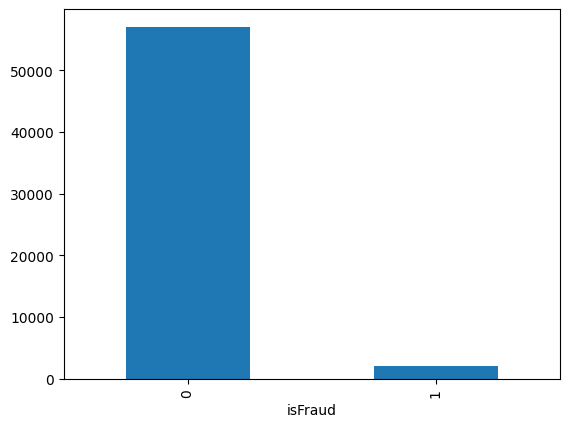

In [ ]:
fraud_data.isFraud.value_counts().plot(kind = 'bar')

Removing columns with more than 20% missing values

In [ ]:
fraud_data = fraud_data[fraud_data.columns[fraud_data.isnull().mean() < 0.2]]

Imputing numerical columns with the true mean

In [ ]:
num_cols = fraud_data.select_dtypes(include =np.number).columns
fraud_data[num_cols] = fraud_data[num_cols].fillna(fraud_data[num_cols].mean())

Imputing the categorical variable with the mode

In [ ]:
cat_cols = fraud_data.select_dtypes(include = 'object').columns
fraud_data[cat_cols] = fraud_data[cat_cols].fillna(fraud_data[cat_cols].mode().iloc[0])

In [ ]:
fraud_data.isnull().sum().sum()

0

In [ ]:
fraud_data.isFraud.value_counts()

,count
isFraud,
0,57049
1,2005


Carrying out One Hot Encoding on the Categorical Variables

In [ ]:
fraud_data = pd.get_dummies(fraud_data,columns = cat_cols)
fraud_data.head()

,TransactionID,isFraud,TransactionDT,TransactionAmt,card1,card2,card3,card5,addr1,addr2,...,P_emaildomain_web.de,P_emaildomain_windstream.net,P_emaildomain_yahoo.co.jp,P_emaildomain_yahoo.co.uk,P_emaildomain_yahoo.com,P_emaildomain_yahoo.com.mx,P_emaildomain_yahoo.de,P_emaildomain_yahoo.es,P_emaildomain_yahoo.fr,P_emaildomain_ymail.com
0,2994681,0,242834,25.000,9803,583.0,150.0,226.0,269.0,87.0,...,False,False,False,False,True,False,False,False,False,False
1,3557242,0,15123000,117.000,7919,194.0,150.0,166.0,181.0,87.0,...,False,False,False,False,False,False,False,False,False,False
2,3327470,0,8378575,73.773,12778,500.0,185.0,224.0,284.0,60.0,...,False,False,False,False,False,False,False,False,False,False
3,3118781,0,2607840,400.000,12316,548.0,150.0,195.0,441.0,87.0,...,False,False,False,False,False,False,False,False,False,False
4,3459772,0,12226544,31.950,9002,453.0,150.0,226.0,264.0,87.0,...,False,False,False,False,True,False,False,False,False,False


Separating the Explanatory and Predictor Variables

In [ ]:
X = fraud_data.drop('isFraud',axis = 1)
y = fraud_data['isFraud']

Separating our data into Training Set and Test set

In [ ]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size = 0.3,random_state = 123)
print(X_train.shape,X_test.shape)

(41337, 249) (17717, 249)


Dealing with Class Imbalance

One of the way to deal with this is by Under Samplibg the majority class and over sampling the minority class in a method known as SMOTE

In [ ]:
from imblearn.over_sampling import SMOTE
sm = SMOTE(random_state =123,sampling_strategy= 1)
X_train,y_train = sm.fit_resample(X_train,y_train)


Fitting a Random Forest Model into our data